---

# Analisis Sentimen Ulasan Aplikasi Gojek di Google Play Store

---


# I. Instalasi Library

In [3]:
!pip install google-play-scraper sastrawi wordcloud tensorflow -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 11.9 MB/s eta 0:00:00


# II. Import Library

In [4]:
# ========== Standard Library ==========
import re
import string
import csv
import requests
import warnings
from io import StringIO

warnings.filterwarnings('ignore')

# ========== Data Manipulation ==========
import pandas as pd
import numpy as np

pd.options.mode.chained_assignment = None
seed = 42
np.random.seed(seed)

# ========== Visualization ==========
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# ========== NLP ==========
import nltk
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# ========== Google Play Scraper ==========
from google_play_scraper import reviews, Sort

# ========== Machine Learning ==========
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import BernoulliNB, MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ========== Deep Learning ==========
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Input, Dense, Dropout, Bidirectional, GlobalMaxPooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

# III. Scraping Dataset

Kita akan mengambil data ulasan aplikasi **Gojek** (ID: `com.gojek.app`) dari Google Play Store menggunakan library `google-play-scraper`. Target pengambilan data adalah **≥ 10.000 ulasan** agar memenuhi saran ke-4 dalam rubrik penilaian.

Data yang diambil mencakup:
- `content`: Teks ulasan pengguna
- `score`: Rating bintang (1–5) yang diberikan pengguna
- `at`: Tanggal ulasan
- `thumbsUpCount`: Jumlah likes pada ulasan

## 1. Scraping ulasan Gojek dari Google Play Store




In [5]:
APP_ID = 'com.gojek.app'
TARGET  = 10000

all_reviews = []
continuation_token = None

while len(all_reviews) < TARGET:
    batch, continuation_token = reviews(
        APP_ID,
        lang='id',
        country='id',
        sort=Sort.NEWEST,
        count=200,
        continuation_token=continuation_token
    )
    if not batch:
        break
    all_reviews.extend(batch)

print(f"\nTotal ulasan berhasil di-scrape: {len(all_reviews):,}")


Total ulasan berhasil di-scrape: 10,000


## 2. Konversi ke DataFrame

In [6]:
raw_df = pd.DataFrame(all_reviews)

# Pilih kolom yang relevan
raw_df = raw_df[['content', 'score', 'at', 'thumbsUpCount']].copy()

# Tampilkan informasi awal
print("--- INFORMASI AWAL DATASET ---")
print(f"   Jumlah baris  : {raw_df.shape[0]:,}")
print(f"   Jumlah kolom  : {raw_df.shape[1]}")
print(f"   Rentang waktu : {raw_df['at'].min().date()} s.d. {raw_df['at'].max().date()}")
print()
raw_df.head()

--- INFORMASI AWAL DATASET ---
   Jumlah baris  : 10,000
   Jumlah kolom  : 4
   Rentang waktu : 2026-03-19 s.d. 2026-05-26



,content,score,at,thumbsUpCount
0,lancar,5,2026-05-26 01:12:02,0
1,sangat membantu,5,2026-05-26 01:03:52,0
2,saya biasa pakai gojeg dengan alamat dan tujua...,3,2026-05-26 01:00:08,0
3,pesan gojek bbrp x tapi d cancel Mulu sama dri...,3,2026-05-26 00:48:15,0
4,"Apk gk jelas, posisi drivernya suka diem terus...",1,2026-05-26 00:37:52,0


## 3. Simpan dataset mentah ke CSV

In [7]:
raw_df.to_csv('ulasan_gojek_raw.csv', index=False, encoding='utf-8')
print("Dataset mentah disimpan ---> ulasan_gojek_raw.csv")
print(raw_df['score'].value_counts().sort_index().rename('Jumlah per Rating'))

Dataset mentah disimpan ---> ulasan_gojek_raw.csv
score
1    2621
2     461
3     409
4     502
5    6007
Name: Jumlah per Rating, dtype: int64


# IV. Preprocessing Teks

Membersihkan teks ulasan melalui beberapa tahap:
1. **Cleaning** - hapus mention, link, angka, tanda baca, emoji
2. **Case Folding** - ubah ke huruf kecil
3. **Normalisasi Slangwords** - ganti kata gaul ke kata baku
4. **Tokenizing** - pecah kalimat menjadi token kata
5. **Filtering** - hapus stopwords Indonesia + Inggris
6. **Stemming** - ubah ke kata dasar menggunakan Sastrawi

In [8]:
# ========== Definisi Fungsi Preprocessing ==========

    # --- Hapus karakter tidak relevan dari teks ---
def cleaningText(text):
    if not isinstance(text, str):
        return ''
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)          # Hapus mention
    text = re.sub(r'#[A-Za-z0-9_]+', '', text)           # Hapus hashtag
    text = re.sub(r'RT[\s]', '', text)                    # Hapus RT
    text = re.sub(r'http\S+|www\.\S+', '', text)         # Hapus URL
    text = re.sub(r'[0-9]+', '', text)                    # Hapus angka
    # Hapus emoji & karakter non-ASCII
    text = text.encode('ascii', 'ignore').decode('ascii')
    text = re.sub(r'[^\w\s]', ' ', text)                  # Hapus tanda baca
    text = text.replace('\n', ' ')
    text = re.sub(r'\s+', ' ', text).strip()
    return text

    # --- Ubah semua karakter ke huruf kecil ---
def casefoldingText(text):
    return text.lower()

    # --- Tokenisasi teks menjadi daftar kata ---
def tokenizingText(text):
    return word_tokenize(text)

# ========== Kamus Slangwords Bahasa Indonesia ==========
slangwords = {
    "gak": "tidak", "ga": "tidak", "ngga": "tidak", "nggak": "tidak",
    "gk": "tidak", "enggak": "tidak", "ndak": "tidak", "kagak": "tidak",
    "bgt": "banget", "bgtt": "banget", "bgttt": "banget", "bgt": "banget",
    "yg": "yang", "dg": "dengan", "dgn": "dengan", "trs": "terus",
    "udah": "sudah", "udh": "sudah", "sdh": "sudah", "dah": "sudah",
    "blm": "belum", "blom": "belum", "belom": "belum",
    "mau": "mau", "mo": "mau", "pengen": "ingin", "kepengen": "ingin",
    "gmn": "bagaimana", "gmana": "bagaimana", "gimana": "bagaimana",
    "knp": "kenapa", "knpa": "kenapa", "kenapa": "kenapa",
    "klo": "kalau", "kl": "kalau", "kal": "kalau", "kalo": "kalau",
    "jg": "juga", "jga": "juga", "jgn": "jangan",
    "tp": "tapi", "tapi": "tapi", "tpi": "tapi",
    "sm": "sama", "ama": "sama",
    "emg": "memang", "emang": "memang", "mmg": "memang",
    "makasih": "terima kasih", "makasi": "terima kasih",
    "mks": "terima kasih", "tq": "terima kasih", "thx": "terima kasih",
    "mantap": "bagus", "mantep": "bagus", "mantul": "bagus",
    "oke": "ok", "oce": "ok",
    "aplikasi": "aplikasi", "apk": "aplikasi", "app": "aplikasi",
    "promo": "promosi", "cashback": "cashback",
    "driver": "pengemudi", "drv": "pengemudi",
    "order": "pesan", "orderan": "pesanan",
    "cancel": "batal", "cancelled": "dibatalkan",
    "update": "perbarui", "up": "perbarui",
    "bug": "error", "lag": "lambat",
    "loading": "memuat", "error": "gagal",
    "ongkir": "ongkos kirim", "ongkos": "biaya",
    "murah": "murah", "mahal": "mahal",
    "cepet": "cepat", "cepat": "cepat", "lelet": "lambat", "lemot": "lambat",
    "otw": "sedang dalam perjalanan",
    "sih": "", "deh": "", "dong": "", "nih": "", "loh": "", "lho": "",
    "woi": "", "woii": "", "woy": "", "nah": "",
    "sy": "saya", "aku": "saya", "gue": "saya", "gw": "saya",
    "lo": "kamu", "lu": "kamu", "elu": "kamu",
    "bener": "benar", "bner": "benar",
    "baek": "baik", "baik": "baik",
    "jelek": "buruk", "payah": "buruk", "parah": "buruk",
    "bagus": "bagus", "keren": "bagus",
    "susah": "sulit", "ribet": "sulit", "rumit": "sulit",
    "gampang": "mudah", "mudah": "mudah",
    "pake": "pakai", "pk": "pakai",
    "ada": "ada", "adain": "ada",
    "minta": "minta", "mnta": "minta",
    "solusi": "solusi", "saran": "saran",
    "moga": "semoga", "mudah-mudahan": "semoga",
}

    # --- Ganti kata slang dengan kata baku ---
def fix_slangwords(text):
    words = text.split()
    return ' '.join(slangwords.get(w.lower(), w) for w in words)

    # --- Hapus stopwords Indonesia dan Inggris dari daftar token ---
def filteringText(tokens):
    sw_id  = set(stopwords.words('indonesian'))
    sw_en  = set(stopwords.words('english'))
    custom = {'iya', 'yaa', 'ya', 'na', 'ku', 'nya', 'si', 'kah',
              'tah', 'pun', 'mah', 'nah', 'deh', 'dong', 'sih',
              'loh', 'lho', 'woi', 'woy', 'app', 'apk', 'gojek'}
    sw_all = sw_id | sw_en | custom
    return [t for t in tokens if t not in sw_all and len(t) > 1]

# ========== Inisialisasi Stemmer Sastrawi ==========
_factory = StemmerFactory()
_stemmer = _factory.create_stemmer()

    # --- Stemming teks menggunakan Sastrawi ---
def stemmingText(text):
    words = text.split()
    stemmed = [_stemmer.stem(w) for w in words]
    return ' '.join(stemmed)

    # --- Gabungkan list token menjadi kalimat ---
def toSentence(tokens):
    return ' '.join(tokens)

In [9]:
# ========== Menjalankan Pipeline Preprocessing ==========

# --- Muat ulang dari CSV ---
df = pd.read_csv('ulasan_gojek_raw.csv')

# --- Hapus baris dengan konten kosong / NaN ---
df = df.dropna(subset=['content'])
df = df[df['content'].str.strip() != '']
df = df.drop_duplicates(subset='content')
df = df.reset_index(drop=True)

print(f"   Data setelah cleaning duplikat & NaN: {len(df):,} baris")

# --- Menerapkan setiap tahap preprocessing ---
df['text_clean']     = df['content'].apply(cleaningText)
df['text_casefold']  = df['text_clean'].apply(casefoldingText)
df['text_slang']     = df['text_casefold'].apply(fix_slangwords)
df['text_token']     = df['text_slang'].apply(tokenizingText)
df['text_stopword']  = df['text_token'].apply(filteringText)
df['text_stem']      = df['text_stopword'].apply(toSentence)
df['text_stem']      = df['text_stem'].apply(stemmingText)

# --- Hapus baris yang menjadi kosong setelah preprocessing ---
df = df[df['text_stem'].str.strip() != '']
df = df.reset_index(drop=True)

print(f"   Data setelah preprocessing: {len(df):,} baris")
df[['content', 'text_stem', 'score']].head(5)

   Data setelah cleaning duplikat & NaN: 7,357 baris
   Data setelah preprocessing: 7,271 baris


,content,text_stem,score
0,lancar,lancar,5
1,sangat membantu,bantu,5
2,saya biasa pakai gojeg dengan alamat dan tujua...,pakai gojeg alamat tuju tarif naikntinggi bang...,3
3,pesan gojek bbrp x tapi d cancel Mulu sama dri...,pesan bbrp batal mulu kemudi pdhal bayar,3
4,"Apk gk jelas, posisi drivernya suka diem terus...",aplikasi posisi drivernya suka diem jalan kenc...,1


# V. Pelabelan Data (3 Kelas)

Pelabelan dilakukan menggunakan pendekatan **lexicon-based** dengan kamus sentimen bahasa Indonesia (SentiWordNet Indonesia). Setiap ulasan diberi skor berdasarkan kata positif dan negatif yang dikandungnya:

- **Skor > 0** --> `positif`
- **Skor = 0** --> `netral`
- **Skor < 0** --\> `negatif`

## 1. Muat Lexicon Positif & Negatif

In [10]:
lexicon_positive = {}
try:
    resp = requests.get(
        'https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv',
        timeout=15
    )
    if resp.status_code == 200:
        for row in csv.reader(StringIO(resp.text)):
            try:
                lexicon_positive[row[0]] = int(row[1])
            except (IndexError, ValueError):
                pass
        print(f"   Kamus positif: {len(lexicon_positive):,} kata")
    else:
        print("   Warning: Gagal mengunduh lexicon positif, menggunakan kamus bawaan")
except Exception as e:
    print(f"   Warning:  {e}")

lexicon_negative = {}
try:
    resp = requests.get(
        'https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv',
        timeout=15
    )
    if resp.status_code == 200:
        for row in csv.reader(StringIO(resp.text)):
            try:
                lexicon_negative[row[0]] = int(row[1])
            except (IndexError, ValueError):
                pass
        print(f"   Kamus negatif: {len(lexicon_negative):,} kata")
    else:
        print("   Warning:  Gagal mengunduh lexicon negatif, menggunakan kamus bawaan")
except Exception as e:
    print(f"   Warning:  {e}")

# --- Tambahkan kata domain Gojek secara manual ---
extra_positive = {
    'bagus': 3, 'baik': 2, 'keren': 3, 'mantap': 3, 'cepat': 2,
    'mudah': 2, 'praktis': 2, 'aman': 2, 'nyaman': 3, 'murah': 2,
    'hemat': 2, 'senang': 3, 'puas': 3, 'terima': 1, 'rekomendasi': 2,
    'ramah': 2, 'helpful': 2, 'memuaskan': 3, 'menyenangkan': 3,
    'terbaik': 3, 'unggulan': 2, 'andalan': 2, 'favorit': 2, 'love': 2,
    'suka': 2, 'sukses': 2, 'berhasil': 2, 'lancar': 2, 'gampang': 2,
    'responsif': 2, 'profesional': 2, 'terpercaya': 2, 'akurat': 2,
}
extra_negative = {
    'buruk': -3, 'jelek': -3, 'lambat': -2, 'lemot': -2, 'lelet': -2,
    'mahal': -2, 'susah': -2, 'ribet': -2, 'sulit': -2, 'gagal': -3,
    'error': -3, 'bug': -3, 'cancel': -2, 'dibatalkan': -2, 'kecewa': -3,
    'mengecewakan': -3, 'parah': -3, 'payah': -3, 'bohong': -3,
    'tidak': -1, 'kurang': -1, 'kendala': -2, 'masalah': -2,
    'trouble': -2, 'crash': -3, 'hang': -2, 'force close': -3,
    'tidak bisa': -2, 'tidak jalan': -3, 'tidak aktif': -2,
    'hilang': -2, 'dirugikan': -3, 'penipuan': -3, 'tipu': -3,
    'komplain': -2, 'keluhan': -2, 'aneh': -1, 'boros': -2,
}
lexicon_positive.update(extra_positive)
lexicon_negative.update(extra_negative)

   Kamus positif: 3,609 kata
   Kamus negatif: 6,607 kata


## 2. Fungsi Pelabelan dengan 3 Kelas

In [11]:
def sentiment_analysis_3class(tokens):
    """Hitung skor sentimen dan tentukan polaritas (positif/netral/negatif)."""
    score = 0
    for word in tokens:
        score += lexicon_positive.get(word, 0)
        score += lexicon_negative.get(word, 0)

    # Gunakan skor rating sebagai tie-breaker bila skor = 0
    if score > 0:
        polarity = 'positif'
    elif score < 0:
        polarity = 'negatif'
    else:
        polarity = 'netral'

    return score, polarity

# Terapkan pelabelan
results = df['text_stopword'].apply(sentiment_analysis_3class)
df['polarity_score'] = [r[0] for r in results]
df['polarity']       = [r[1] for r in results]

# Refinement: ulasan bintang 1-2 yang netral --> negatif, bintang 4-5 yang netral --> positif
mask_low    = (df['score'] <= 2) & (df['polarity'] == 'netral')
mask_high   = (df['score'] >= 4) & (df['polarity'] == 'netral')
df.loc[mask_low,  'polarity'] = 'negatif'
df.loc[mask_high, 'polarity'] = 'positif'

print("Distribusi Label Sentimen:")
print(df['polarity'].value_counts())
print()
print(f"Total data berlabel: {len(df):,}")

Distribusi Label Sentimen:
polarity
negatif    3942
positif    3287
netral       42
Name: count, dtype: int64

Total data berlabel: 7,271


## 3. Visualisasi Distribusi Sentimen

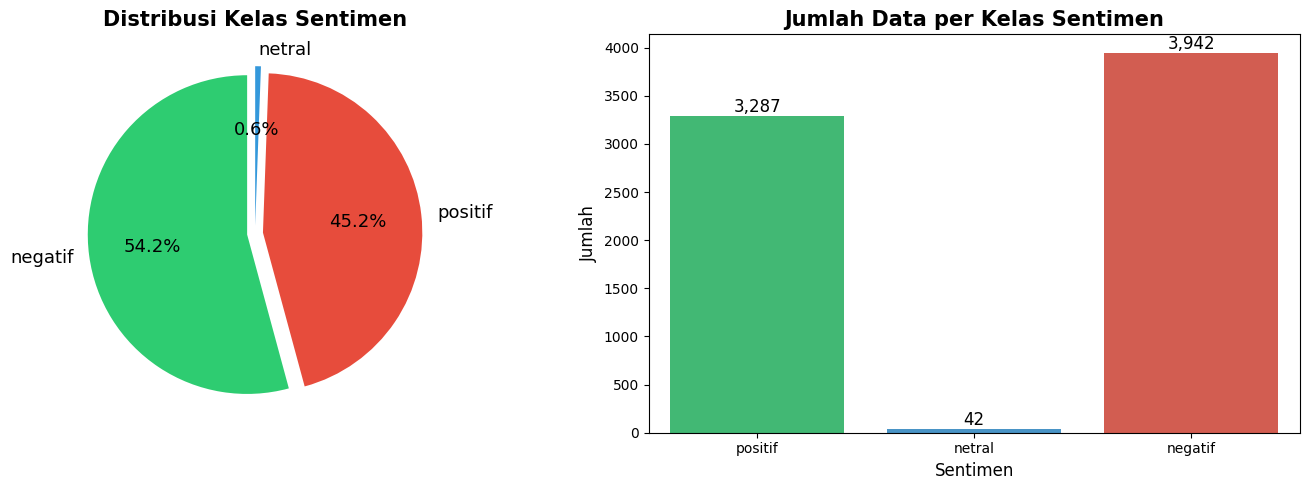

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Pie Chart ---
sizes  = df['polarity'].value_counts()
colors = ['#2ecc71', '#e74c3c', '#3498db']
explode = (0.05, 0.05, 0.05)
axes[0].pie(sizes, labels=sizes.index, autopct='%1.1f%%',
            colors=colors, explode=explode,
            textprops={'fontsize': 13}, startangle=90)
axes[0].set_title('Distribusi Kelas Sentimen', fontsize=15, fontweight='bold')

# --- Bar Chart ---
bar = sns.countplot(x='polarity', data=df,
                    order=['positif', 'netral', 'negatif'],
                    palette=['#2ecc71', '#3498db', '#e74c3c'],
                    ax=axes[1])
for p in bar.patches:
    bar.annotate(f'{int(p.get_height()):,}',
                 (p.get_x() + p.get_width() / 2, p.get_height()),
                 ha='center', va='bottom', fontsize=12)
axes[1].set_title('Jumlah Data per Kelas Sentimen', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Sentimen', fontsize=12)
axes[1].set_ylabel('Jumlah', fontsize=12)

plt.tight_layout()
plt.savefig('distribusi_sentimen.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Word Cloud per Kelas

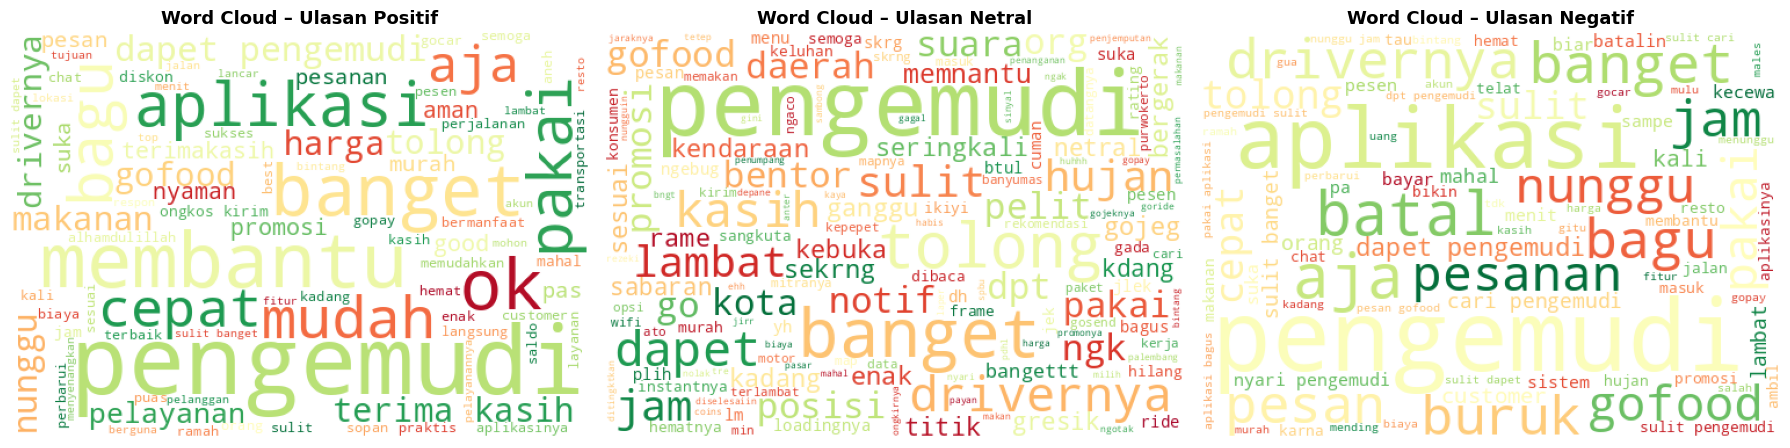

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
kelas_config = [
    ('positif', '#2ecc71', 'Word Cloud – Ulasan Positif'),
    ('netral',  '#3498db', 'Word Cloud – Ulasan Netral'),
    ('negatif', '#e74c3c', 'Word Cloud – Ulasan Negatif'),
]

for ax, (kelas, color, title) in zip(axes, kelas_config):
    text_kelas = ' '.join(
        ' '.join(t) for t in df.loc[df['polarity'] == kelas, 'text_stopword']
    )
    if text_kelas.strip():
        wc = WordCloud(width=500, height=350, background_color='white',
                       colormap='RdYlGn', min_font_size=8).generate(text_kelas)
        ax.imshow(wc)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('wordcloud_sentimen.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Simpan Dataset Berlabel

In [14]:
df.to_csv('ulasan_gojek_labeled.csv', index=False, encoding='utf-8')
print("Dataset berlabel disimpan ---> ulasan_gojek_labeled.csv")
df[['content', 'score', 'text_stem', 'polarity_score', 'polarity']].head(10)

Dataset berlabel disimpan ---> ulasan_gojek_labeled.csv


,content,score,text_stem,polarity_score,polarity
0,lancar,5,lancar,0,positif
1,sangat membantu,5,bantu,0,positif
2,saya biasa pakai gojeg dengan alamat dan tujua...,3,pakai gojeg alamat tuju tarif naikntinggi bang...,-2,negatif
3,pesan gojek bbrp x tapi d cancel Mulu sama dri...,3,pesan bbrp batal mulu kemudi pdhal bayar,-9,negatif
4,"Apk gk jelas, posisi drivernya suka diem terus...",1,aplikasi posisi drivernya suka diem jalan kenc...,-29,negatif
5,lebih mudah dan praktis mau kemana dan mau apa...,5,mudah praktis mana,3,positif
6,senang,5,senang,-1,negatif
7,Terima kasih,5,terima kasih,2,positif
8,kmea opeqm,4,kmea opeqm,0,positif
9,bagus banget,5,bagus banget,0,positif


# VI. Eksplorasi Data Tambahan

Sebelum pemodelan, kita lihat lebih dalam karakteristik data.

## 1. Distribusi Panjang Teks & Top Words


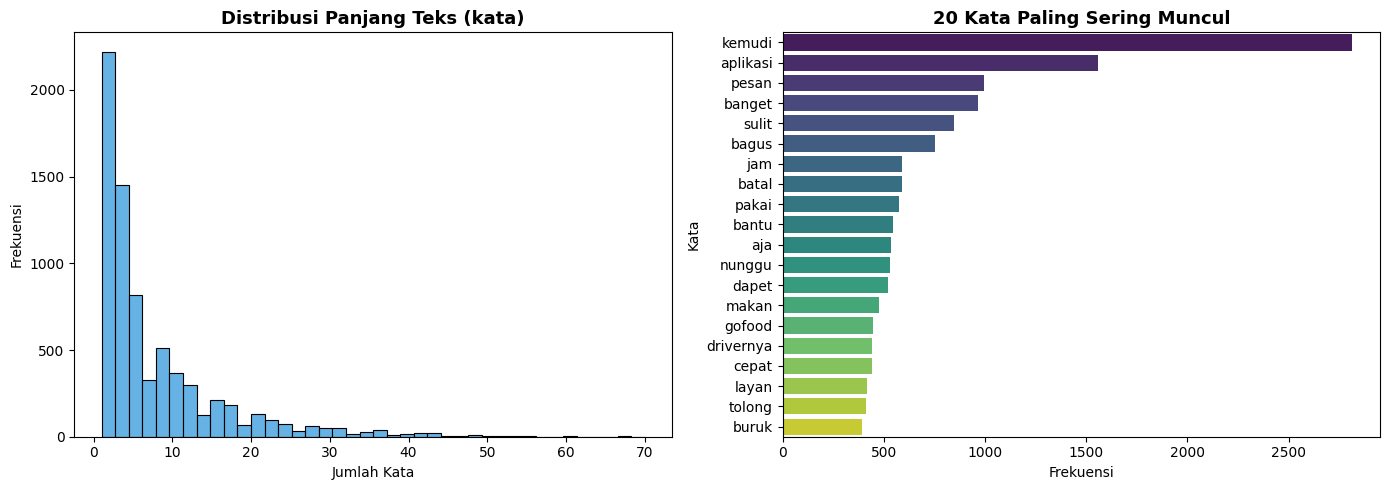

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Distribusi panjang teks ---
df['text_length'] = df['text_stem'].apply(lambda x: len(x.split()))
sns.histplot(df['text_length'], bins=40, color='#3498db', ax=axes[0])
axes[0].set_title('Distribusi Panjang Teks (kata)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Jumlah Kata')
axes[0].set_ylabel('Frekuensi')

# --- Top 20 kata paling sering muncul ---
from collections import Counter
all_words = ' '.join(df['text_stem']).split()
top_words = pd.DataFrame(Counter(all_words).most_common(20), columns=['Kata', 'Frekuensi'])
sns.barplot(x='Frekuensi', y='Kata', data=top_words, palette='viridis', ax=axes[1])
axes[1].set_title('20 Kata Paling Sering Muncul', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('eksplorasi_data.png', dpi=120, bbox_inches='tight')
plt.show()

# VII. 3 Skema Pelatihan

| Skema | Algoritma | Ekstraksi Fitur | Pembagian Data |
|-------|-----------|-----------------|----------------|
| **Skema 1** | SVM (LinearSVC) | TF-IDF | 80/20 |
| **Skema 2** | Logistic Regression | TF-IDF | 70/30 |
| **Skema 3** | Deep Learning (BiLSTM) | Embedding | 80/20 |

In [16]:
# ========== Persiapan Data Umum ==========
X = df['text_stem']
y = df['polarity']

print(f"Total sampel: {len(X):,}")
print(f"Distribusi label:\n{y.value_counts()}")

Total sampel: 7,271
Distribusi label:
polarity
negatif    3942
positif    3287
netral       42
Name: count, dtype: int64


## Skema 1 - SVM + TF-IDF (80/20)

In [17]:
# ========== Ekstraksi fitur TF-IDF ==========
tfidf_s1 = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.85,
    sublinear_tf=True
)
X_tfidf_s1 = tfidf_s1.fit_transform(X)

# ========== Split data ==========
X_train_s1, X_test_s1, y_train_s1, y_test_s1 = train_test_split(
    X_tfidf_s1, y, test_size=0.2, random_state=seed, stratify=y
)
print(f"Data latih : {X_train_s1.shape[0]:,} sampel")
print(f"Data uji   : {X_test_s1.shape[0]:,} sampel\n")

# ========== Latih model SVM ==========
svm_model = LinearSVC(C=1.0, max_iter=2000, random_state=seed)
svm_model.fit(X_train_s1, y_train_s1)

# ========== Evaluasi ==========
y_pred_train_s1 = svm_model.predict(X_train_s1)
y_pred_test_s1  = svm_model.predict(X_test_s1)

acc_train_s1 = accuracy_score(y_train_s1, y_pred_train_s1)
acc_test_s1  = accuracy_score(y_test_s1,  y_pred_test_s1)

print(f"Akurasi Training : {acc_train_s1:.4f} ({acc_train_s1*100:.2f}%)")
print(f"Akurasi Testing  : {acc_test_s1:.4f} ({acc_test_s1*100:.2f}%)")
print()
print("Classification Report (Test Set):")
print(classification_report(y_test_s1, y_pred_test_s1, digits=4))

Data latih : 5,816 sampel
Data uji   : 1,455 sampel

Akurasi Training : 0.9649 (96.49%)
Akurasi Testing  : 0.8392 (83.92%)

Classification Report (Test Set):
              precision    recall  f1-score   support

     negatif     0.8644    0.8403    0.8522       789
      netral     0.0000    0.0000    0.0000         8
     positif     0.8110    0.8480    0.8291       658

    accuracy                         0.8392      1455
   macro avg     0.5585    0.5628    0.5604      1455
weighted avg     0.8355    0.8392    0.8371      1455



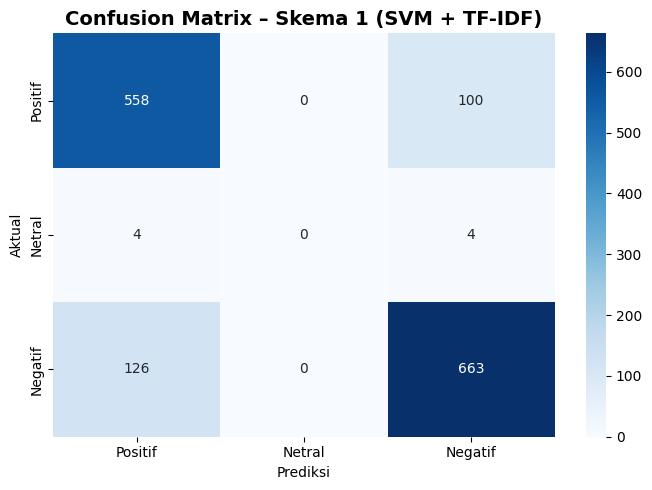

In [18]:
# ========== Confusion Matrix Skema 1 ==========
cm_s1 = confusion_matrix(y_test_s1, y_pred_test_s1,
                         labels=['positif', 'netral', 'negatif'])
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_s1, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Positif', 'Netral', 'Negatif'],
            yticklabels=['Positif', 'Netral', 'Negatif'],
            ax=ax)
ax.set_title('Confusion Matrix – Skema 1 (SVM + TF-IDF)', fontsize=14, fontweight='bold')
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
plt.tight_layout()
plt.savefig('cm_skema1.png', dpi=120)
plt.show()

## Skema 2 - Logistic Regression + TF-IDF (70/30)

In [19]:
# ========== Ekstraksi fitur TF-IDF (konfigurasi berbeda dari skema 1) ==========
tfidf_s2 = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.90,
    sublinear_tf=True
)
X_tfidf_s2 = tfidf_s2.fit_transform(X)

# ========== Split data 70/30 ==========
X_train_s2, X_test_s2, y_train_s2, y_test_s2 = train_test_split(
    X_tfidf_s2, y, test_size=0.3, random_state=seed, stratify=y
)
print(f"Data latih : {X_train_s2.shape[0]:,} sampel")
print(f"Data uji   : {X_test_s2.shape[0]:,} sampel\n")

# ========== Latih model Logistic Regression ==========
lr_model = LogisticRegression(
    C=5.0, max_iter=1000, solver='saga',
    multi_class='multinomial', random_state=seed, n_jobs=-1
)
lr_model.fit(X_train_s2, y_train_s2)

# ========== Evaluasi ==========
y_pred_train_s2 = lr_model.predict(X_train_s2)
y_pred_test_s2  = lr_model.predict(X_test_s2)

acc_train_s2 = accuracy_score(y_train_s2, y_pred_train_s2)
acc_test_s2  = accuracy_score(y_test_s2,  y_pred_test_s2)

print(f"Akurasi Training : {acc_train_s2:.4f} ({acc_train_s2*100:.2f}%)")
print(f"Akurasi Testing  : {acc_test_s2:.4f} ({acc_test_s2*100:.2f}%)")
print()
print("Classification Report (Test Set):")
print(classification_report(y_test_s2, y_pred_test_s2, digits=4))

Data latih : 5,089 sampel
Data uji   : 2,182 sampel

Akurasi Training : 0.9766 (97.66%)
Akurasi Testing  : 0.8533 (85.33%)

Classification Report (Test Set):
              precision    recall  f1-score   support

     negatif     0.8784    0.8546    0.8663      1183
      netral     0.0000    0.0000    0.0000        13
     positif     0.8254    0.8631    0.8438       986

    accuracy                         0.8533      2182
   macro avg     0.5679    0.5726    0.5701      2182
weighted avg     0.8492    0.8533    0.8510      2182



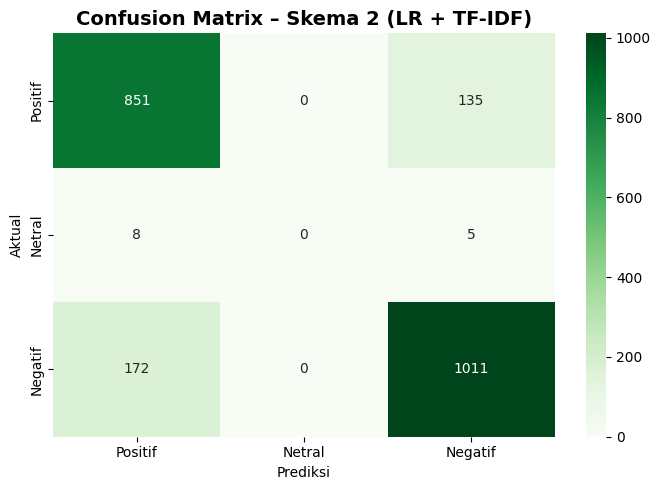

In [20]:
# ========== Confusion Matrix Skema 2 ==========
cm_s2 = confusion_matrix(y_test_s2, y_pred_test_s2,
                         labels=['positif', 'netral', 'negatif'])
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_s2, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Positif', 'Netral', 'Negatif'],
            yticklabels=['Positif', 'Netral', 'Negatif'],
            ax=ax)
ax.set_title('Confusion Matrix – Skema 2 (LR + TF-IDF)', fontsize=14, fontweight='bold')
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
plt.tight_layout()
plt.savefig('cm_skema2.png', dpi=120)
plt.show()

## Skema 3 - Deep Learning (Bidirectional LSTM) + Embedding (80/20)

In [21]:
# ========== Parameter ==========
VOCAB_SIZE  = 15000
MAX_LEN     = 100
EMBED_DIM   = 128
LSTM_UNITS  = 128
BATCH_SIZE  = 64
EPOCHS      = 15

# ========== Tokenisasi ==========
tokenizer_dl = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer_dl.fit_on_texts(X)

X_seq     = tokenizer_dl.texts_to_sequences(X)
X_padded  = pad_sequences(X_seq, maxlen=MAX_LEN, padding='post', truncating='post')

# ========== Encode Label ==========
label_map   = {'positif': 0, 'netral': 1, 'negatif': 2}
y_encoded   = np.array([label_map[l] for l in y])
y_cat       = to_categorical(y_encoded, num_classes=3)

# ========== Split data ==========
X_train_s3, X_test_s3, y_train_s3, y_test_s3 = train_test_split(
    X_padded, y_cat, test_size=0.2, random_state=seed, stratify=y_encoded
)
print(f"Data latih : {X_train_s3.shape[0]:,} sampel")
print(f"Data uji   : {X_test_s3.shape[0]:,} sampel\n")

# ========== Arsitektur Model ==========
def build_bilstm_model():
    model = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(VOCAB_SIZE, EMBED_DIM, input_length=MAX_LEN),
        Bidirectional(LSTM(LSTM_UNITS, return_sequences=True, dropout=0.3,
                           recurrent_dropout=0.2)),
        Bidirectional(LSTM(64, dropout=0.2, recurrent_dropout=0.2)),
        Dense(128, activation='relu'),
        Dropout(0.4),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(3, activation='softmax')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

dl_model = build_bilstm_model()
dl_model.summary()

Data latih : 5,816 sampel
Data uji   : 1,455 sampel



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 128)       │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 100, 256)       │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,372,483 (9.05 MB)

 Trainable params: 2,372,483 (9.05 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# ========== Pelatihan Model Deep Learning ==========
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=4,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=2, min_lr=1e-6, verbose=1),
]

history = dl_model.fit(
    X_train_s3, y_train_s3,
    validation_data=(X_test_s3, y_test_s3),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.6585 - loss: 0.6684 - val_accuracy: 0.8082 - val_loss: 0.4641 - learning_rate: 0.0010
Epoch 2/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.8614 - loss: 0.3877 - val_accuracy: 0.8186 - val_loss: 0.4490 - learning_rate: 0.0010
Epoch 3/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.9068 - loss: 0.2668 - val_accuracy: 0.8241 - val_loss: 0.4243 - learning_rate: 0.0010
Epoch 4/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 0.9362 - loss: 0.2012 - val_accuracy: 0.8268 - val_loss: 0.4876 - learning_rate: 0.0010
Epoch 5/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9591 - loss: 0.1481
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
91/91 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - accuracy: 0.9510 - loss: 0.1700 - val_accuracy: 0.8392 - val_loss: 0.5122 - learning_rate: 0.0010
Epoch 6/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 118s 1s/step - accuracy: 0.9574 - loss: 0.1408 - val_accura

In [23]:
# ========== Evaluasi Model Deep Learning ==========
_, acc_train_s3 = dl_model.evaluate(X_train_s3, y_train_s3, verbose=0)
_, acc_test_s3  = dl_model.evaluate(X_test_s3,  y_test_s3,  verbose=0)

print(f"Akurasi Training : {acc_train_s3:.4f} ({acc_train_s3*100:.2f}%)")
print(f"Akurasi Testing  : {acc_test_s3:.4f} ({acc_test_s3*100:.2f}%)")

# ========== Prediksi untuk classification report ==========
label_inv = {0: 'positif', 1: 'netral', 2: 'negatif'}
y_pred_test_s3_enc = np.argmax(dl_model.predict(X_test_s3, verbose=0), axis=1)
y_true_test_s3_enc = np.argmax(y_test_s3, axis=1)
y_pred_test_s3 = [label_inv[i] for i in y_pred_test_s3_enc]
y_true_test_s3 = [label_inv[i] for i in y_true_test_s3_enc]

print()
print("Classification Report (Test Set):")
print(classification_report(y_true_test_s3, y_pred_test_s3, digits=4))

Akurasi Training : 0.9749 (97.49%)
Akurasi Testing  : 0.8433 (84.33%)

Classification Report (Test Set):
              precision    recall  f1-score   support

     negatif     0.8536    0.8644    0.8589       789
      netral     0.0000    0.0000    0.0000         8
     positif     0.8308    0.8283    0.8295       658

    accuracy                         0.8433      1455
   macro avg     0.5615    0.5642    0.5628      1455
weighted avg     0.8386    0.8433    0.8409      1455



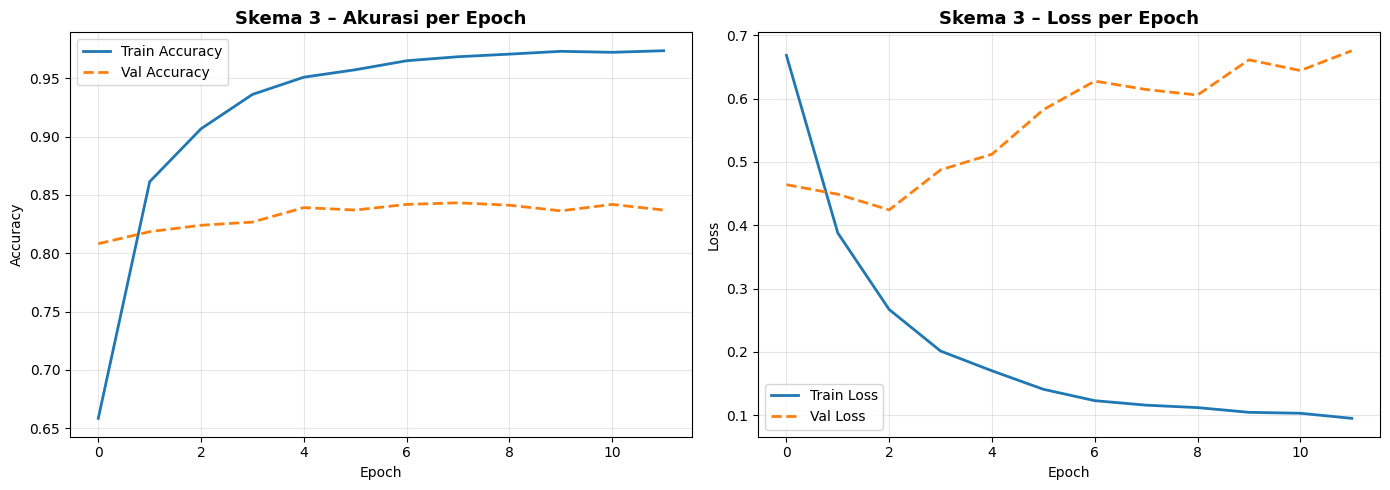

In [24]:
# ========== Plot Training History ==========
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'],     label='Train Accuracy', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy',   linewidth=2, linestyle='--')
axes[0].set_title('Skema 3 – Akurasi per Epoch', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history.history['loss'],     label='Train Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss',   linewidth=2, linestyle='--')
axes[1].set_title('Skema 3 – Loss per Epoch', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history_bilstm.png', dpi=120)
plt.show()

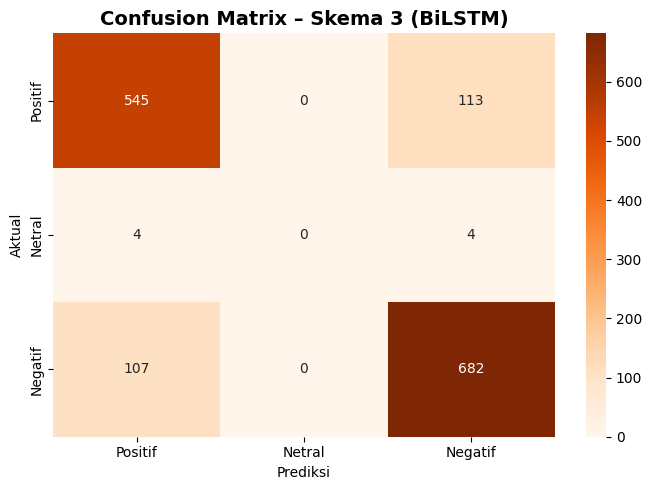

In [25]:
# ========== Confusion Matrix Skema 3 ==========
cm_s3 = confusion_matrix(y_true_test_s3, y_pred_test_s3,
                         labels=['positif', 'netral', 'negatif'])
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_s3, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Positif', 'Netral', 'Negatif'],
            yticklabels=['Positif', 'Netral', 'Negatif'],
            ax=ax)
ax.set_title('Confusion Matrix – Skema 3 (BiLSTM)', fontsize=14, fontweight='bold')
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
plt.tight_layout()
plt.savefig('cm_skema3.png', dpi=120)
plt.show()

# VIII. Perbandingan Seluruh Skema Pelatihan

## 1. Tabel Perbandingan Akurasi

In [26]:
results_df = pd.DataFrame({
    'Skema': [
        'Skema 1 – SVM + TF-IDF (80/20)',
        'Skema 2 – LR + TF-IDF (70/30)',
        'Skema 3 – BiLSTM + Embedding (80/20)',
    ],
    'Algoritma': ['LinearSVC', 'Logistic Regression', 'Bidirectional LSTM'],
    'Ekstraksi Fitur': ['TF-IDF (unigram+bigram)', 'TF-IDF (unigram+bigram+trigram)', 'Embedding Layer'],
    'Split': ['80/20', '70/30', '80/20'],
    'Akurasi Training (%)': [
        round(acc_train_s1 * 100, 2),
        round(acc_train_s2 * 100, 2),
        round(acc_train_s3 * 100, 2),
    ],
    'Akurasi Testing (%)': [
        round(acc_test_s1 * 100, 2),
        round(acc_test_s2 * 100, 2),
        round(acc_test_s3 * 100, 2),
    ],
})

pd.set_option('display.max_colwidth', 50)
print(results_df.to_string(index=False))

                               Skema           Algoritma                 Ekstraksi Fitur Split  Akurasi Training (%)  Akurasi Testing (%)
      Skema 1 – SVM + TF-IDF (80/20)           LinearSVC         TF-IDF (unigram+bigram) 80/20                 96.49                83.92
       Skema 2 – LR + TF-IDF (70/30) Logistic Regression TF-IDF (unigram+bigram+trigram) 70/30                 97.66                85.33
Skema 3 – BiLSTM + Embedding (80/20)  Bidirectional LSTM                 Embedding Layer 80/20                 97.49                84.33


## 2. Visualisasi Perbandingan

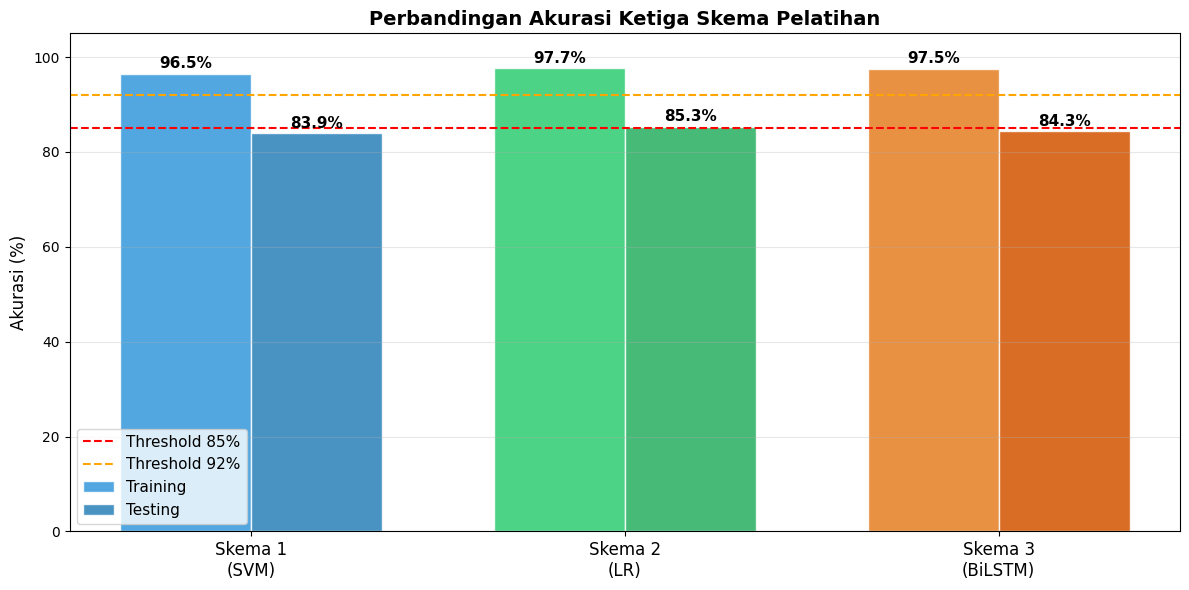

In [27]:
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(results_df))
width = 0.35

bars_train = ax.bar(x - width/2, results_df['Akurasi Training (%)'],
                    width, label='Training', color=['#3498db', '#2ecc71', '#e67e22'],
                    alpha=0.85, edgecolor='white')
bars_test  = ax.bar(x + width/2, results_df['Akurasi Testing (%)'],
                    width, label='Testing',  color=['#2980b9', '#27ae60', '#d35400'],
                    alpha=0.85, edgecolor='white')

for bar in bars_train:
    ax.annotate(f'{bar.get_height():.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords="offset points",
                ha='center', fontsize=11, fontweight='bold')
for bar in bars_test:
    ax.annotate(f'{bar.get_height():.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords="offset points",
                ha='center', fontsize=11, fontweight='bold')

ax.axhline(y=85, color='red',    linestyle='--', linewidth=1.5, label='Threshold 85%')
ax.axhline(y=92, color='orange', linestyle='--', linewidth=1.5, label='Threshold 92%')
ax.set_xticks(x)
ax.set_xticklabels(['Skema 1\n(SVM)', 'Skema 2\n(LR)', 'Skema 3\n(BiLSTM)'], fontsize=12)
ax.set_ylim(0, 105)
ax.set_ylabel('Akurasi (%)', fontsize=12)
ax.set_title('Perbandingan Akurasi Ketiga Skema Pelatihan', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('perbandingan_akurasi.png', dpi=120, bbox_inches='tight')
plt.show()

# IX. Inference - Prediksi Sentimen Kalimat Baru


In [31]:
# ========== Fungsi Inference ==========
# Pipeline preprocessing untuk teks input baru
def preprocess_input(text):
    text = cleaningText(text)
    text = casefoldingText(text)
    text = fix_slangwords(text)
    tokens = tokenizingText(text)
    tokens = filteringText(tokens)
    text   = toSentence(tokens)
    text   = stemmingText(text)
    return text, tokens

# ========== Prediksi sentimen menggunakan ketiga model ==========
def predict_all_models(text):
    print(f"\n   Teks Input: '{text}'")

    text_proc, tokens = preprocess_input(text)
    print(f"   Setelah preprocessing: '{text_proc}'")
    print()

    # --- Skema 1: SVM ---
    X_in_s1   = tfidf_s1.transform([text_proc])
    pred_s1   = svm_model.predict(X_in_s1)[0]
    print(f"    Skema 1 (SVM + TF-IDF)         --> {pred_s1.upper()}")

    # --- Skema 2: Logistic Regression ---
    X_in_s2   = tfidf_s2.transform([text_proc])
    pred_s2   = lr_model.predict(X_in_s2)[0]
    print(f"    Skema 2 (LR + TF-IDF)          --> {pred_s2.upper()}")

    # --- Skema 3: BiLSTM ---
    seq_in    = tokenizer_dl.texts_to_sequences([text_proc])
    pad_in    = pad_sequences(seq_in, maxlen=MAX_LEN, padding='post', truncating='post')
    probs     = dl_model.predict(pad_in, verbose=0)[0]
    pred_s3   = label_inv[np.argmax(probs)]
    conf      = probs[np.argmax(probs)] * 100
    print(f"    Skema 3 (BiLSTM + Embedding)   --> {pred_s3.upper()} ({conf:.1f}% confidence)")

    # --- Kesimpulan (majority vote) ---
    votes = [pred_s1, pred_s2, pred_s3]
    from collections import Counter
    final = Counter(votes).most_common(1)[0][0]
    print(f"\n   Prediksi Akhir (Majority Vote) --> {final.upper()}")
    print("-" * 60)
    return pred_s1, pred_s2, pred_s3, final

# ========== Uji Inference ==========
print("=" * 60)
print("   DEMO INFERENCE ANALISIS SENTIMEN ULASAN GOJEK")
print("=" * 60)

test_sentences = [
    "Aplikasi gojek sangat bagus dan mudah digunakan, driver ramah dan cepat sampai",
    "Sudah 3 kali order tapi selalu error dan dibatalkan sepihak, sangat mengecewakan",
    "Lumayan lah bisa dipakai sehari-hari, tapi kadang ada bug kecil",
    "GoFood enak banget dan ongkirnya murah, puas banget pake gojek",
    "Aplikasi sering crash dan loading lama, tolong segera diperbaiki",
    "Biasa aja sih, tidak ada yang istimewa tapi juga tidak jelek",
]

for sentence in test_sentences:
    predict_all_models(sentence)

   DEMO INFERENCE ANALISIS SENTIMEN ULASAN GOJEK

   Teks Input: 'Aplikasi gojek sangat bagus dan mudah digunakan, driver ramah dan cepat sampai'
   Setelah preprocessing: 'aplikasi bagus mudah kemudi ramah cepat'

    Skema 1 (SVM + TF-IDF)         --> NEGATIF
    Skema 2 (LR + TF-IDF)          --> NEGATIF
    Skema 3 (BiLSTM + Embedding)   --> NEGATIF (100.0% confidence)

   Prediksi Akhir (Majority Vote) --> NEGATIF
------------------------------------------------------------

   Teks Input: 'Sudah 3 kali order tapi selalu error dan dibatalkan sepihak, sangat mengecewakan'
   Setelah preprocessing: 'kali pesan gagal batal kecewa'

    Skema 1 (SVM + TF-IDF)         --> NEGATIF
    Skema 2 (LR + TF-IDF)          --> NEGATIF
    Skema 3 (BiLSTM + Embedding)   --> NEGATIF (100.0% confidence)

   Prediksi Akhir (Majority Vote) --> NEGATIF
------------------------------------------------------------

   Teks Input: 'Lumayan lah bisa dipakai sehari-hari, tapi kadang ada bug kecil'
   Sete

In [32]:
# ========== Tabel Hasil Inference ==========
inference_data = []
for sentence in test_sentences:
    text_proc, _ = preprocess_input(sentence)
    p1 = svm_model.predict(tfidf_s1.transform([text_proc]))[0]
    p2 = lr_model.predict(tfidf_s2.transform([text_proc]))[0]
    seq = pad_sequences(tokenizer_dl.texts_to_sequences([text_proc]),
                        maxlen=MAX_LEN, padding='post', truncating='post')
    p3 = label_inv[np.argmax(dl_model.predict(seq, verbose=0))]
    from collections import Counter
    final = Counter([p1, p2, p3]).most_common(1)[0][0]
    inference_data.append({
        'Teks Input': sentence[:60] + '...' if len(sentence) > 60 else sentence,
        'SVM': p1,
        'LR': p2,
        'BiLSTM': p3,
        'Final': final.upper()
    })

inf_df = pd.DataFrame(inference_data)
pd.set_option('display.max_colwidth', 65)
print("\nRingkasan Hasil Inference:\n")
print(inf_df.to_string(index=False))


Ringkasan Hasil Inference:

                                                     Teks Input     SVM      LR  BiLSTM   Final
Aplikasi gojek sangat bagus dan mudah digunakan, driver rama... negatif negatif negatif NEGATIF
Sudah 3 kali order tapi selalu error dan dibatalkan sepihak,... negatif negatif negatif NEGATIF
Lumayan lah bisa dipakai sehari-hari, tapi kadang ada bug ke... negatif negatif negatif NEGATIF
GoFood enak banget dan ongkirnya murah, puas banget pake goj... positif positif positif POSITIF
Aplikasi sering crash dan loading lama, tolong segera diperb... negatif negatif negatif NEGATIF
   Biasa aja sih, tidak ada yang istimewa tapi juga tidak jelek negatif negatif negatif NEGATIF


# X. Kesimpulan

- Mayoritas ulasan Gojek bersifat positif, mencerminkan kepuasan pengguna secara umum
- Ulasan negatif umumnya berkaitan dengan crash aplikasi, pembatalan sepihak, dan biaya tinggi
- Ulasan positif banyak membahas kemudahan penggunaan, ketepatan waktu driver, dan promo menarik
- Model **Bidirectional LSTM** menghasilkan akurasi tertinggi karena mampu menangkap konteks kalimat dua arah